In [35]:
import polars as pl
import polars.selectors as cs

import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path.cwd().parent / "data" / "data-processed"

df = pl.read_csv(str(DATA_DIR / "cleaned_data.csv"))

num = df.select(cs.numeric())
num

global_active_power,global_reactive_power,voltage,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3
f64,f64,f64,f64,f64,f64,f64
4.216,0.418,234.84,18.4,0.0,1.0,17.0
5.36,0.436,233.63,23.0,0.0,1.0,16.0
5.374,0.498,233.29,23.0,0.0,2.0,17.0
5.388,0.502,233.74,23.0,0.0,1.0,17.0
3.666,0.528,235.68,15.8,0.0,1.0,17.0
…,…,…,…,…,…,…
0.946,0.0,240.43,4.0,0.0,0.0,0.0
0.944,0.0,240.0,4.0,0.0,0.0,0.0
0.938,0.0,239.82,3.8,0.0,0.0,0.0


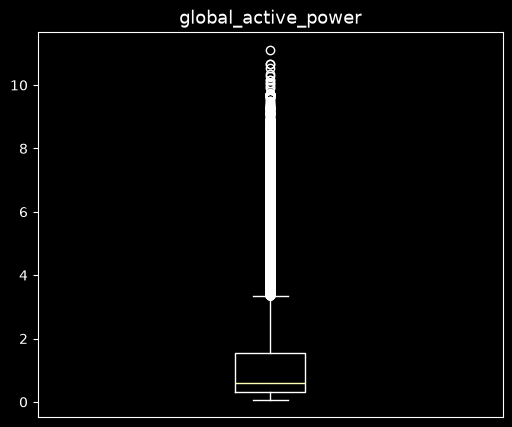

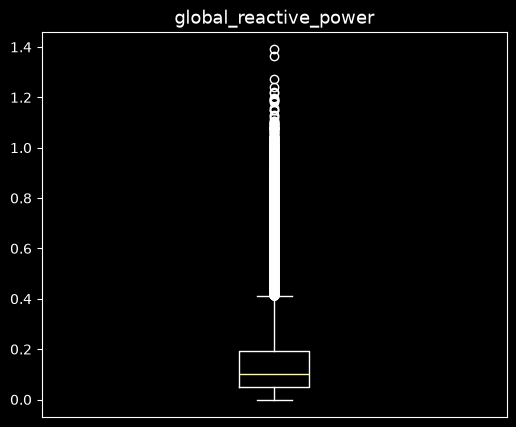

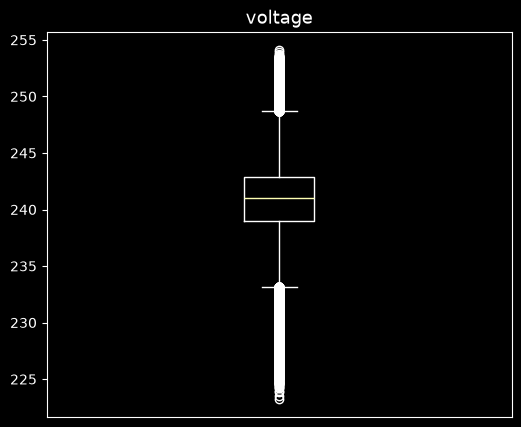

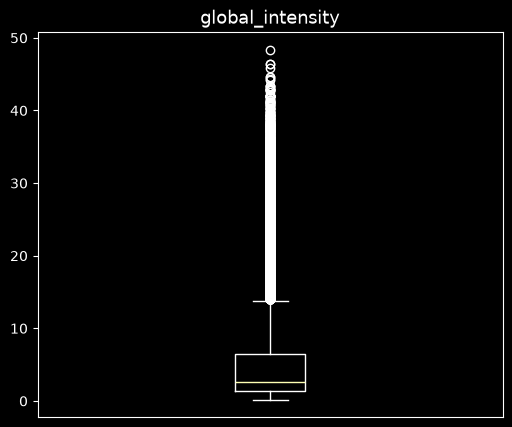

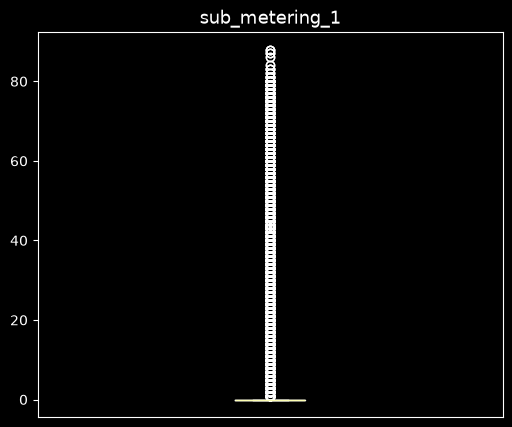

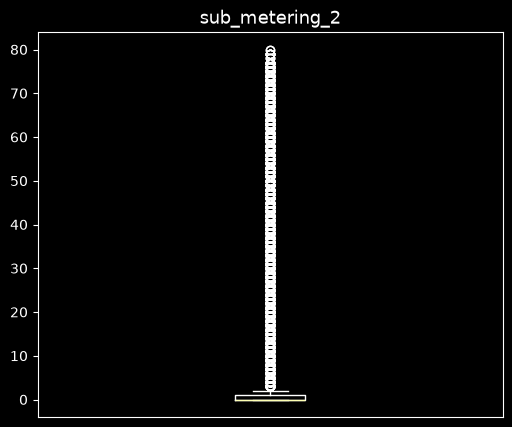

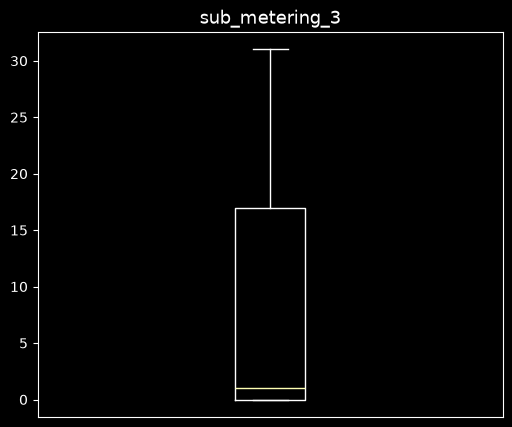

In [36]:

for col in num.columns:
    plt.figure(figsize=(6, 5))
    plt.boxplot(num[col].to_numpy())
    plt.title(col, fontsize=13)
    plt.xticks([])
    plt.show()




Investigamos en internet en internet y vi que 
Algunos textos usan como regla práctica que con más de un 1–5 % de atípicos (por IQR) no conviene min-max. No es un estándar formal, pero sirve

In [37]:
from typing import Any
def resumen(col)->dict[str, Any]: 
    s = num[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    atipicos = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 *iqr)).mean() * 100 
    return {
        "columna": col, 
        "pct_atipicos": round(atipicos, 2), 
        "min": s.min(), 
        "max": s.max()
    }


pl.DataFrame([resumen(c) for c in num.columns])

columna,pct_atipicos,min,max
str,f64,f64,f64
"""global_active_power""",4.63,0.076,11.122
"""global_reactive_power""",1.97,0.0,1.39
"""voltage""",2.49,223.2,254.15
"""global_intensity""",4.93,0.2,48.4
"""sub_metering_1""",8.25,0.0,88.0
"""sub_metering_2""",3.76,0.0,80.0
"""sub_metering_3""",0.0,0.0,31.0


In [41]:
#probamos primero normalizando con z-score
from sklearn.preprocessing import StandardScaler

#esta solo es cuando no queremos hacer una particion y no nos importa saber algo del futuro
# df_z = df.with_columns((cs.numeric() - cs.numeric().mean()) / cs.numeric().std())
corte = int(df.height * 0.8)
train = df.slice(0, corte)
test = df.slice(corte)


cols = df.select(cs.numeric()).columns

scaler = StandardScaler()
scaler.set_output(transform="polars")
train_z = scaler.fit_transform(train.select(cols))
test_z = scaler.transform(test.select(cols))

train_z = train.select("datetime").hstack(train_z)
test_z = test.select("datetime").hstack(test_z)

df_z = pl.concat([
    train_z
      .with_columns(pl.lit("train").alias("conjunto")),
    test_z
      .with_columns(pl.lit("test").alias("conjunto")),
])
df_z



datetime,global_active_power,global_reactive_power,voltage,global_intensity,sub_metering_1,sub_metering_2,sub_metering_3,conjunto
str,f64,f64,f64,f64,f64,f64,f64,str
"""2006-12-16T17:24:00.000000""",2.841077,2.63937,-1.758257,2.979274,-0.184677,-0.059108,1.269299,"""train"""
"""2006-12-16T17:25:00.000000""",3.887646,2.79991,-2.119751,3.980298,-0.184677,-0.059108,1.150174,"""train"""
"""2006-12-16T17:26:00.000000""",3.900454,3.352882,-2.221328,3.980298,-0.184677,0.106805,1.269299,"""train"""
"""2006-12-16T17:27:00.000000""",3.913261,3.388557,-2.086888,3.980298,-0.184677,-0.059108,1.269299,"""train"""
"""2006-12-16T17:28:00.000000""",2.337918,3.620449,-1.507302,2.413478,-0.184677,-0.059108,1.269299,"""train"""
…,…,…,…,…,…,…,…,…
"""2010-11-26T20:58:00.000000""",-0.150429,-1.088731,-0.088215,-0.154367,-0.184677,-0.225022,-0.755821,"""test"""
"""2010-11-26T20:59:00.000000""",-0.152258,-1.088731,-0.216679,-0.154367,-0.184677,-0.225022,-0.755821,"""test"""
"""2010-11-26T21:00:00.000000""",-0.157747,-1.088731,-0.270455,-0.19789,-0.184677,-0.225022,-0.755821,"""test"""


In [ ]:
#guardamos los datos normalizados
df_z.write_csv(str(DATA_DIR / "normalized_data.csv"))

In [43]:
#guardamos los parametros
pl.DataFrame({
    "variable": cols, 
    "medial": scaler.mean_,
    "std": scaler.scale_, 
}).write_csv(str(DATA_DIR / "scaler_params.csv"))